In [1]:
import torch
import torch.nn as nn
import math
import hashlib

In [2]:
def vis_color(nodes, color):
    # colors a set of nodes (for visualization)
    for n in nodes:
        setattr(n, '_vis_color', color)

In [3]:
class Value:
    """ stores a single scalar value and its gradient """

    def __init__(self, data, _children=(), _op='', label=''):
        self.data = data
        self.grad = 0
        # internal variables used for autograd graph construction
        self._backward = lambda: None
        self._prev = set(_children)
        self._op = _op # the op that produced this node, for graphviz / debugging / etc
        self.label = label
        self.h = hashlib.sha3_512() # Python 3.6+
        if label != '':
            self._vis_color = None
            self.h.update(bytes(label, "utf-8"))
    
    def __add__(self, other):
        other = other if isinstance(other, Value) else Value(other)
        out = Value(self.data + other.data, (self, other), '+')

        def _backward():
            self.grad += out.grad
            other.grad += out.grad
            print(" add backward ", self.grad, other.grad, out )
        out._backward = _backward

        return out

    def __mul__(self, other):
        other = other if isinstance(other, Value) else Value(other)
        out = Value(self.data * other.data, (self, other), '*')

        def _backward():
            self.grad += other.data * out.grad
            other.grad += self.data * out.grad
            print(" mul backward ", self.grad, other.grad, out )
        out._backward = _backward

        return out

    def exp(self):
        x = self.data
        out = Value(math.exp(x), (self, ), 'exp')
        
        def _backward():
          self.grad += out.data * out.grad # NOTE: in the video I incorrectly used = instead of +=. Fixed here.
          print(" exp backward ", self.grad, out )
        out._backward = _backward
        
        return out
    
    def __pow__(self, other):
        assert isinstance(other, (int, float)), "only supporting int/float powers for now"
        out = Value(self.data**other, (self,), f'**{other}')

        def _backward():
            self.grad += (other * self.data**(other-1)) * out.grad
            print(" pow backward ", self.grad, out, self.data, other, out.grad )
        out._backward = _backward

        return out

    def relu(self):
        out = Value(0 if self.data < 0 else self.data, (self,), 'ReLU')

        def _backward():
            self.grad += (out.data > 0) * out.grad
        out._backward = _backward

        return out

    # sigmoid activation function
    def sigmoid(self):
        x = self.data
        t = 1/(1+(math.exp(-x)))
        out = Value(t, (self, ), 'sigmoid')
        
        def _backward():
            f = 1/(1+(math.exp(-x)))
            self.grad += (f*(1 - f)) * out.grad
            print(" sigmoid backward ", f, self.grad, out )
        out._backward = _backward
        return out

    
    def log(self):
        # natural logarithm ln(x)
        if self.data <= 0:
            raise ValueError("log(x) requires x > 0")
    
        out = Value(math.log(self.data), (self,), 'log')
    
        def _backward():
            # d/dx log(x) = 1/x
            self.grad += (1.0 / self.data) * out.grad
            print(" log backward ", self.grad, out )
    
        out._backward = _backward
        return out
    
    def backward(self):

        # topological order all of the children in the graph
        topo = []
        visited = set()
        def build_topo(v):
            print( " show all v here : ", v)
            if v not in visited:
                print( "v ", v)
                visited.add(v)
                for child in v._prev:
                    print( "child ", child)
                    build_topo(child)
                topo.append(v)
        build_topo(self)

        # go one variable at a time and apply the chain rule to get its gradient
        self.grad = 1
        for v in reversed(topo):
            v._backward()

    def __neg__(self): # -self
        return self * -1

    def __radd__(self, other): # other + self
        return self + other

    def __sub__(self, other): # self - other
        return self + (-other)

    def __rsub__(self, other): # other - self
        return other + (-self)

    def __rmul__(self, other): # other * self
        return self * other

    def __truediv__(self, other): # self / other
        return self * other**-1

    def __rtruediv__(self, other): # other / self
        return other * self**-1

    def __repr__(self):
        return f"Value(data={self.data}, grad={self.grad})"

In [4]:
from graphviz import Digraph

def trace(root):
    nodes, edges = set(), set()
    def build(v):
        if v not in nodes:
            nodes.add(v)
            for child in v._prev:
                edges.add((child, v))
                build(child)
    build(root)
    return nodes, edges

ORIGINAL_GLOBAL = None

def vis_color(nodes, color):
    # colors a set of nodes (for visualization)
    global ORIGINAL_GLOBAL
    original = set()
    print( " enter to vis color " )
    for n in nodes:
        print(n)
        print(n.label)
        if (n.label != ''):
            setattr(n, '_vis_color', color)
            original.add(n)

    print(40*'-')
    print(original)
    ORIGINAL_GLOBAL = original
    for k in original:
        print(k.label, k.h.hexdigest())
        print(k)
    print(40*'-')


def draw_dot(root, format='svg', rankdir='LR', outfile='graph'):
    """
    format: png | svg | ...
    rankdir: TB (top to bottom graph) | LR (left to right)
    """
    assert rankdir in ['LR', 'TB']
    nodes, edges = trace(root)
    print("nodes")
    print(nodes)
    print("edges")
    print(edges)
    dot = Digraph(format=format, graph_attr={'rankdir': rankdir, 'nodesep': '0.1', 'ranksep': '0.4'}) #, node_attr={'rankdir': 'TB'})

    #vis_color(nodes, "lightgreen")
    vis_color(nodes, "yellow")
    
    for n in nodes:
        print(n)

        fillcolor = n._vis_color if hasattr(n, '_vis_color') else "white"
        dot.node(name=str(hash(n)), label = "{ %s | data %.4f | grad %.4f }" % (n.label, n.data, n.grad), shape='record', style='filled', fillcolor=fillcolor, width='0.1', height='0.1', fontsize='10')
        
        if n._op:
            dot.node(name=str(hash(n)) + n._op, label=n._op, width='0.1', height='0.1', fontsize='10')
            dot.edge(str(hash(n)) + n._op, str(hash(n)))
    
    for n1, n2 in edges:
        dot.edge(str(hash(n1)), str(hash(n2)) + n2._op)

    # render here
    return dot

    # this creates 2 files ( graph.svg and graph ) on disk
    #dot.render(outfile, format=format)

In [5]:
# Perform the test from exercise 7-1 again.

In [6]:
x00 = Value(2.0, label='x00')
x01 = Value(3.0, label='x01')

 show all v here :  Value(data=35.0, grad=0)
v  Value(data=35.0, grad=0)
child  Value(data=8.0, grad=0)
 show all v here :  Value(data=8.0, grad=0)
v  Value(data=8.0, grad=0)
child  Value(data=2.0, grad=0)
 show all v here :  Value(data=2.0, grad=0)
v  Value(data=2.0, grad=0)
child  Value(data=27.0, grad=0)
 show all v here :  Value(data=27.0, grad=0)
v  Value(data=27.0, grad=0)
child  Value(data=3.0, grad=0)
 show all v here :  Value(data=3.0, grad=0)
v  Value(data=3.0, grad=0)
 add backward  1 1 Value(data=35.0, grad=1)
 pow backward  27.0 Value(data=27.0, grad=1) 3.0 3 1
 pow backward  12.0 Value(data=8.0, grad=1) 2.0 3 1
nodes
{Value(data=35.0, grad=1), Value(data=8.0, grad=1), Value(data=3.0, grad=27.0), Value(data=2.0, grad=12.0), Value(data=27.0, grad=1)}
edges
{(Value(data=3.0, grad=27.0), Value(data=27.0, grad=1)), (Value(data=8.0, grad=1), Value(data=35.0, grad=1)), (Value(data=2.0, grad=12.0), Value(data=8.0, grad=1)), (Value(data=27.0, grad=1), Value(data=35.0, grad=1))}
 e

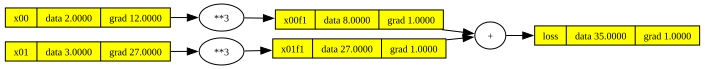

In [7]:
x00f1 = x00 ** 3; x00f1.label = 'x00f1'
x01f1 = x01 ** 3; x01f1.label = 'x01f1'

loss = x00f1 + x01f1; loss.label = 'loss'

loss.backward()

x00 -= 0.01 * x00.grad
x01 -= 0.01 * x01.grad

draw_dot(loss)

 show all v here :  Value(data=26.991089, grad=0)
v  Value(data=26.991089, grad=0)
child  Value(data=6.644671999999999, grad=0)
 show all v here :  Value(data=6.644671999999999, grad=0)
v  Value(data=6.644671999999999, grad=0)
child  Value(data=1.88, grad=0)
 show all v here :  Value(data=1.88, grad=0)
v  Value(data=1.88, grad=0)
child  Value(data=-0.12, grad=0)
 show all v here :  Value(data=-0.12, grad=0)
v  Value(data=-0.12, grad=0)
child  Value(data=2.0, grad=12.0)
 show all v here :  Value(data=2.0, grad=12.0)
v  Value(data=2.0, grad=12.0)
child  Value(data=20.346417, grad=0)
 show all v here :  Value(data=20.346417, grad=0)
v  Value(data=20.346417, grad=0)
child  Value(data=2.73, grad=0)
 show all v here :  Value(data=2.73, grad=0)
v  Value(data=2.73, grad=0)
child  Value(data=3.0, grad=27.0)
 show all v here :  Value(data=3.0, grad=27.0)
v  Value(data=3.0, grad=27.0)
child  Value(data=-0.27, grad=0)
 show all v here :  Value(data=-0.27, grad=0)
v  Value(data=-0.27, grad=0)
 add 

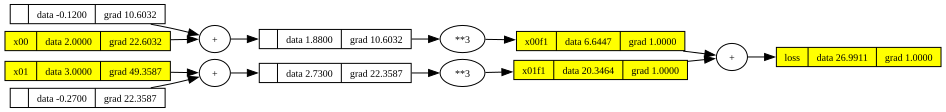

In [8]:
x00f1 = x00 ** 3; x00f1.label = 'x00f1'
x01f1 = x01 ** 3; x01f1.label = 'x01f1'

loss = x00f1 + x01f1; loss.label = 'loss'

loss.backward()

x00 -= 0.01 * x00.grad
x01 -= 0.01 * x01.grad

draw_dot(loss)

In [9]:
# second test 

In [10]:
from graphviz import Digraph

def trace(root):
    nodes, edges = set(), set()
    def build(v):
        if v not in nodes:
            nodes.add(v)
            for child in v._prev:
                edges.add((child, v))
                build(child)
    build(root)
    return nodes, edges

ORIGINAL_GLOBAL = None

def vis_color(nodes, color):
    # colors a set of nodes (for visualization)
    global ORIGINAL_GLOBAL
    original = set()
    #print( " enter to vis color " )
    for n in nodes:
        #print(n)
        #print(n.label)
        if (n.label != ''):
            setattr(n, '_vis_color', color)
            original.add(n)

    #print(40*'-')
    #print(original)
    ORIGINAL_GLOBAL = original
    #for k in original:
    #    print(k.label, k.h.hexdigest())
    #    print(k)
    #print(40*'-')


def draw_dot(root, format='svg', rankdir='LR', outfile='graph'):
    """
    format: png | svg | ...
    rankdir: TB (top to bottom graph) | LR (left to right)
    """
    assert rankdir in ['LR', 'TB']
    nodes, edges = trace(root)
    #print("nodes")
    #print(nodes)
    #print("edges")
    #print(edges)
    dot = Digraph(format=format, graph_attr={'rankdir': rankdir, 'nodesep': '0.1', 'ranksep': '0.4'}) #, node_attr={'rankdir': 'TB'})

    #vis_color(nodes, "lightgreen")
    vis_color(nodes, "yellow")
    
    for n in nodes:
        #print(n)

        fillcolor = n._vis_color if hasattr(n, '_vis_color') else "white"
        dot.node(name=str(hash(n)), label = "{ %s | data %.4f | grad %.4f }" % (n.label, n.data, n.grad), shape='record', style='filled', fillcolor=fillcolor, width='0.1', height='0.1', fontsize='10')
        
        if n._op:
            dot.node(name=str(hash(n)) + n._op, label=n._op, width='0.1', height='0.1', fontsize='10')
            dot.edge(str(hash(n)) + n._op, str(hash(n)))
    
    for n1, n2 in edges:
        dot.edge(str(hash(n1)), str(hash(n2)) + n2._op)

    # render here
    #return dot

    # this creates 2 files ( graph.svg and graph ) on disk
    dot.render(outfile, format=format)

In [11]:
# micrograd branch 1

In [12]:
n1 = Value(0.2477, label = 'n1')
n2 = Value(2.1216, label = 'n2')
n3 = Value(-0.2116, label = 'n3')
n4 = Value(0.4789, label = 'n4')
n5 = Value(-0.4290, label = 'n5')
n6 = Value(1.0829, label = 'n6')
n7 = Value(1.6881, label = 'n7')
n8 = Value(-0.7816, label = 'n8')
n9 = Value(-0.0902, label = 'n9')
n10 = Value(0.2235, label = 'n10')

In [13]:
n1a = n1.exp(); n1a.label = 'n1a'
n2a = n2.exp(); n2a.label = 'n2a'
n3a = n3.exp(); n3a.label = 'n3a'
n4a = n4.exp(); n4a.label = 'n4a'
n5a = n5.exp(); n5a.label = 'n5a'
n6a = n6.exp(); n6a.label = 'n6a'
n7a = n7.exp(); n7a.label = 'n7a'
n8a = n8.exp(); n8a.label = 'n8a'
n9a = n9.exp(); n9a.label = 'n9a'
n10a = n10.exp(); n10a.label = 'n10a'

loss1 = n1a + n2a + n3a + n4a + n5a + n6a + n7a + n8a + n9a + n10a; loss1.label = 'loss1'

# clear grads
n1.grad = 0
n2.grad = 0
n3.grad = 0
n4.grad = 0
n5.grad = 0
n6.grad = 0
n7.grad = 0
n8.grad = 0
n9.grad = 0
n10.grad = 0

loss1.backward()

# update 
LR = 0.2
n1 -= LR * n1.grad
n2 -= LR * n2.grad
n3 -= LR * n3.grad
n4 -= LR * n4.grad
n5 -= LR * n5.grad
n6 -= LR * n6.grad
n7 -= LR * n7.grad
n8 -= LR * n8.grad
n9 -= LR * n9.grad
n10 -= LR * n10.grad


 show all v here :  Value(data=23.68459169376059, grad=0)
v  Value(data=23.68459169376059, grad=0)
child  Value(data=22.434146053484127, grad=0)
 show all v here :  Value(data=22.434146053484127, grad=0)
v  Value(data=22.434146053484127, grad=0)
child  Value(data=0.9137484173115791, grad=0)
 show all v here :  Value(data=0.9137484173115791, grad=0)
v  Value(data=0.9137484173115791, grad=0)
child  Value(data=-0.0902, grad=0)
 show all v here :  Value(data=-0.0902, grad=0)
v  Value(data=-0.0902, grad=0)
child  Value(data=21.52039763617255, grad=0)
 show all v here :  Value(data=21.52039763617255, grad=0)
v  Value(data=21.52039763617255, grad=0)
child  Value(data=21.062724488038533, grad=0)
 show all v here :  Value(data=21.062724488038533, grad=0)
v  Value(data=21.062724488038533, grad=0)
child  Value(data=15.653531020276834, grad=0)
 show all v here :  Value(data=15.653531020276834, grad=0)
v  Value(data=15.653531020276834, grad=0)
child  Value(data=2.9532315161194407, grad=0)
 show all

In [14]:
draw_dot(loss1)

In [15]:
# pytorch

In [16]:
def _loss_exp(x):
    print("raw")
    print(x)
    print(" after exp() " )
    print(x.exp())
    return x.exp()

In [17]:
# initialize

In [18]:
torch.manual_seed(3409)

xs = torch.randn(2,10, requires_grad=True)
ys = torch.tensor([9,4])

In [19]:
xs.data

tensor([[ 0.2477,  2.1216, -0.2116,  0.4789, -0.4290,  1.0829,  1.6881, -0.7816,
         -0.0902,  0.2235],
        [-0.5434, -0.8391, -1.9117, -1.9223, -0.4209, -0.2874,  0.7715,  0.7912,
          0.2874, -0.4553]])

In [20]:
# forward pass

In [21]:
#loss = softmax(xs)
#loss=nl(pred, ys)
loss = _loss_exp(xs)
loss = loss.sum(-1)
print(loss)

xs.grad = None
loss[0].backward()

LR = 0.2
xs.data += -LR * xs.grad

raw
tensor([[ 0.2477,  2.1216, -0.2116,  0.4789, -0.4290,  1.0829,  1.6881, -0.7816,
         -0.0902,  0.2235],
        [-0.5434, -0.8391, -1.9117, -1.9223, -0.4209, -0.2874,  0.7715,  0.7912,
          0.2874, -0.4553]], requires_grad=True)
 after exp() 
tensor([[1.2811, 8.3445, 0.8093, 1.6143, 0.6511, 2.9532, 5.4089, 0.4577, 0.9137,
         1.2504],
        [0.5808, 0.4321, 0.1478, 0.1463, 0.6565, 0.7502, 2.1630, 2.2060, 1.3330,
         0.6342]], grad_fn=<ExpBackward0>)
tensor([23.6842,  9.0499], grad_fn=<SumBackward1>)


In [22]:
xs.grad

tensor([[1.2811, 8.3445, 0.8093, 1.6143, 0.6511, 2.9532, 5.4089, 0.4577, 0.9137,
         1.2504],
        [0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
         0.0000]])

In [23]:
xs.data

tensor([[-0.0085,  0.4527, -0.3735,  0.1560, -0.5593,  0.4923,  0.6063, -0.8731,
         -0.2730, -0.0266],
        [-0.5434, -0.8391, -1.9117, -1.9223, -0.4209, -0.2874,  0.7715,  0.7912,
          0.2874, -0.4553]])

In [24]:
# full graph for cross entropy

In [25]:
def softmax(x): 
    s1 = x
    print( " raw " , s1)
    s2 = x.exp()
    print(" exp " , s2)
    s3 = x.exp().sum()
    print(" sum " , s3)
    s4 = x.exp().sum(-1)
    print(" sum(-1) " , s4)
    s5 = (x.exp().sum(-1)).unsqueeze(-1)
    print(s5)
    s6 = x.exp() / (x.exp().sum(-1)).unsqueeze(-1)
    print(s6)
    return x.exp() / (x.exp().sum(-1)).unsqueeze(-1)
    
def nl(input, target): 
    print("input", input)
    print("target", target)

    s1 = range(target.shape[0])
    s2 = target.shape[0]
    print(s1)
    print(s2)

    s3 = input[range(target.shape[0]), target]
    print( " s3 " , s3)

    s4 = -input[range(target.shape[0]), target]
    print( " s4 negative : ", s4)

    s5 = -input[range(target.shape[0]), target].log()
    print( " s5 log ", s5)

    p_loss = -input[range(target.shape[0]), target].log().mean()
    print( "loss" , p_loss)
    
    return -input[range(target.shape[0]), target].log().mean()

In [26]:
# pytorch 

In [27]:
torch.manual_seed(3409)

xs = torch.randn(2,10, requires_grad=True)
ys = torch.tensor([9,4])

In [28]:
xs.data

tensor([[ 0.2477,  2.1216, -0.2116,  0.4789, -0.4290,  1.0829,  1.6881, -0.7816,
         -0.0902,  0.2235],
        [-0.5434, -0.8391, -1.9117, -1.9223, -0.4209, -0.2874,  0.7715,  0.7912,
          0.2874, -0.4553]])

In [29]:
pred = softmax(xs)
loss=nl(pred, ys)

xs.grad = None

loss.backward()

LR = 0.2
xs.data += -LR * xs.grad

 raw  tensor([[ 0.2477,  2.1216, -0.2116,  0.4789, -0.4290,  1.0829,  1.6881, -0.7816,
         -0.0902,  0.2235],
        [-0.5434, -0.8391, -1.9117, -1.9223, -0.4209, -0.2874,  0.7715,  0.7912,
          0.2874, -0.4553]], requires_grad=True)
 exp  tensor([[1.2811, 8.3445, 0.8093, 1.6143, 0.6511, 2.9532, 5.4089, 0.4577, 0.9137,
         1.2504],
        [0.5808, 0.4321, 0.1478, 0.1463, 0.6565, 0.7502, 2.1630, 2.2060, 1.3330,
         0.6342]], grad_fn=<ExpBackward0>)
 sum  tensor(32.7341, grad_fn=<SumBackward0>)
 sum(-1)  tensor([23.6842,  9.0499], grad_fn=<SumBackward1>)
tensor([[23.6842],
        [ 9.0499]], grad_fn=<UnsqueezeBackward0>)
tensor([[0.0541, 0.3523, 0.0342, 0.0682, 0.0275, 0.1247, 0.2284, 0.0193, 0.0386,
         0.0528],
        [0.0642, 0.0477, 0.0163, 0.0162, 0.0725, 0.0829, 0.2390, 0.2438, 0.1473,
         0.0701]], grad_fn=<DivBackward0>)
input tensor([[0.0541, 0.3523, 0.0342, 0.0682, 0.0275, 0.1247, 0.2284, 0.0193, 0.0386,
         0.0528],
        [0.0642, 0.047

In [30]:
xs.data

tensor([[ 0.2423,  2.0864, -0.2151,  0.4721, -0.4318,  1.0704,  1.6652, -0.7835,
         -0.0941,  0.3182],
        [-0.5498, -0.8439, -1.9134, -1.9239, -0.3281, -0.2957,  0.7476,  0.7668,
          0.2727, -0.4623]])

In [31]:
xs.grad

tensor([[ 0.0270,  0.1762,  0.0171,  0.0341,  0.0137,  0.0623,  0.1142,  0.0097,
          0.0193, -0.4736],
        [ 0.0321,  0.0239,  0.0082,  0.0081, -0.4637,  0.0414,  0.1195,  0.1219,
          0.0736,  0.0350]])

In [32]:
loss

tensor(2.7825, grad_fn=<NegBackward0>)

In [33]:
# micrograd

In [34]:
# initialize branch 1
n1 = Value(0.2477, label = 'n1')
n2 = Value(2.1216, label = 'n2')
n3 = Value(-0.2116, label = 'n3')
n4 = Value(0.4789, label = 'n4')
n5 = Value(-0.4290, label = 'n5')
n6 = Value(1.0829, label = 'n6')
n7 = Value(1.6881, label = 'n7')
n8 = Value(-0.7816, label = 'n8')
n9 = Value(-0.0902, label = 'n9')
n10 = Value(0.2235, label = 'n10')

# initialize branch 2
m1 = Value(-0.5434, label = 'm1')
m2 = Value(-0.8391, label = 'm2')
m3 = Value(-1.9117, label = 'm3')
m4 = Value(-1.922, label = 'm4')
m5 = Value(-0.4209, label = 'm5')
m6 = Value(-0.2874, label = 'm6')
m7 = Value(0.7715, label = 'm7')
m8 = Value(0.7912, label = 'm8')
m9 = Value(0.2874, label = 'm9')
m10 = Value(-0.455, label = 'm10')

In [35]:

# exp()
n1a = n1.exp(); n1a.label = 'n1a'
n2a = n2.exp(); n2a.label = 'n2a'
n3a = n3.exp(); n3a.label = 'n3a'
n4a = n4.exp(); n4a.label = 'n4a'
n5a = n5.exp(); n5a.label = 'n5a'
n6a = n6.exp(); n6a.label = 'n6a'
n7a = n7.exp(); n7a.label = 'n7a'
n8a = n8.exp(); n8a.label = 'n8a'
n9a = n9.exp(); n9a.label = 'n9a'
n10a = n10.exp(); n10a.label = 'n10a'

loss1 = n1a + n2a + n3a + n4a + n5a + n6a + n7a + n8a + n9a + n10a; loss1.label = 'loss1'

m1a = m1.exp(); m1a.label = 'm1a'
m2a = m2.exp(); m2a.label = 'm2a'
m3a = m3.exp(); m3a.label = 'm3a'
m4a = m4.exp(); m4a.label = 'm4a'
m5a = m5.exp(); m5a.label = 'm5a'
m6a = m6.exp(); m6a.label = 'm6a'
m7a = m7.exp(); m7a.label = 'm7a'
m8a = m8.exp(); m8a.label = 'm8a'
m9a = m9.exp(); m9a.label = 'm9a'
m10a = m10.exp(); m10a.label = 'm10a'

loss2 = m1a + m2a + m3a + m4a + m5a + m6a + m7a + m8a + m9a + m10a; loss2.label = 'loss2'

# first branch
p1 = n1a / loss1
p2 = n2a / loss1
p3 = n3a / loss1
p4 = n4a / loss1
p5 = n5a / loss1
p6 = n6a / loss1
p7 = n7a / loss1
p8 = n8a / loss1
p9 = n9a / loss1
p10 = n10a / loss1

# second branch
p11 = m1a / loss2
p12 = m2a / loss2
p13 = m3a / loss2
p14 = m4a / loss2
p15 = m5a / loss2
p16 = m6a / loss2
p17 = m7a / loss2
p18 = m8a / loss2
p19 = m9a / loss2
p20 = m10a / loss2

last_loss = -(p10.log() + p15.log()) / 2

# clear grads
n1.grad = 0
n2.grad = 0
n3.grad = 0
n4.grad = 0
n5.grad = 0
n6.grad = 0
n7.grad = 0
n8.grad = 0
n9.grad = 0
n10.grad = 0

# clear grads
m1.grad = 0
m2.grad = 0
m3.grad = 0
m4.grad = 0
m5.grad = 0
m6.grad = 0
m7.grad = 0
m8.grad = 0
m9.grad = 0
m10.grad = 0

last_loss.backward()

# update 
LR = 0.2
n1 -= LR * n1.grad
n2 -= LR * n2.grad
n3 -= LR * n3.grad
n4 -= LR * n4.grad
n5 -= LR * n5.grad
n6 -= LR * n6.grad
n7 -= LR * n7.grad
n8 -= LR * n8.grad
n9 -= LR * n9.grad
n10 -= LR * n10.grad

m1 -= LR * m1.grad
m2 -= LR * m2.grad
m3 -= LR * m3.grad
m4 -= LR * m4.grad
m5 -= LR * m5.grad
m6 -= LR * m6.grad
m7 -= LR * m7.grad
m8 -= LR * m8.grad
m9 -= LR * m9.grad
m10 -= LR * m10.grad

 show all v here :  Value(data=2.782502209411421, grad=0)
v  Value(data=2.782502209411421, grad=0)
child  Value(data=5.565004418822842, grad=0)
 show all v here :  Value(data=5.565004418822842, grad=0)
v  Value(data=5.565004418822842, grad=0)
child  Value(data=-1, grad=0)
 show all v here :  Value(data=-1, grad=0)
v  Value(data=-1, grad=0)
child  Value(data=-5.565004418822842, grad=0)
 show all v here :  Value(data=-5.565004418822842, grad=0)
v  Value(data=-5.565004418822842, grad=0)
child  Value(data=-2.6236797216178616, grad=0)
 show all v here :  Value(data=-2.6236797216178616, grad=0)
v  Value(data=-2.6236797216178616, grad=0)
child  Value(data=0.07253546084340425, grad=0)
 show all v here :  Value(data=0.07253546084340425, grad=0)
v  Value(data=0.07253546084340425, grad=0)
child  Value(data=0.11049558411115268, grad=0)
 show all v here :  Value(data=0.11049558411115268, grad=0)
v  Value(data=0.11049558411115268, grad=0)
child  Value(data=9.05013542436278, grad=0)
 show all v here 

In [36]:
last_loss

Value(data=2.782502209411421, grad=1)

In [37]:
draw_dot(last_loss)